# 07 · ¿Se nota la fiesta en internet?

Si no hay conteo de asistentes, ¿hay alguna señal **consistente año con año** del interés en la fiesta? Las visitas diarias a Wikipedia son una de las pocas series públicas, gratuitas y continuas (desde julio de 2015). No miden asistentes; miden curiosidad.

Pregunta: ¿suben las visitas al artículo de Magdalena de Kino durante las fiestas, y cambia esa señal con los años?

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

import pandas as pd
import plotly.graph_objects as go

from src import config, tema
from src import procesamiento as proc

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

In [2]:
wiki = proc.leer_wikipedia()
wiki.groupby(["proyecto", "articulo"])["visitas"].agg(["sum", "mean", "max"]).round(1)

sum  mean   max
proyecto     articulo                                  
en.wikipedia Magdalena_de_Kino       124667  30.3  1578
es.wikipedia Eusebio_Francisco_Kino  218263  53.1   832
             Magdalena_(Sonora)       17954   5.0    69
             Magdalena_de_Kino       233423  56.8   579

Usamos el artículo en español `Magdalena_de_Kino`, el de mayor audiencia. Comparamos el promedio diario dentro de la ventana de fiestas contra el promedio del resto del año. Excluimos 2015 (serie incompleta) y 2026 (año en curso).

In [3]:
es = wiki[(wiki["proyecto"] == "es.wikipedia") & (wiki["articulo"] == "Magdalena_de_Kino")].copy()
es["anio"] = es["fecha"].dt.year
es["en_fiestas"] = proc.en_ventana_fiestas(es["fecha"])
indice = (
    es[es["anio"].between(2016, 2025)]
    .groupby(["anio", "en_fiestas"])["visitas"].mean().unstack()
    .rename(columns={True: "diario_en_fiestas", False: "diario_resto_del_anio"})
)
indice["indice_fiestas"] = indice["diario_en_fiestas"] / indice["diario_resto_del_anio"]
indice.round(2)

en_fiestas,diario_resto_del_anio,diario_en_fiestas,indice_fiestas
anio,,,
2016,62.81,125.55,2.00
2017,61.79,98.91,1.60
2018,65.39,97.73,1.49
2019,74.19,111.27,1.50
2020,54.32,65.73,1.21
2021,49.48,41.45,0.84
2022,43.72,55.73,1.27
2023,59.21,73.09,1.23
2024,54.15,58.00,1.07


In [4]:
print(f"Índice promedio 2016-2025: {indice['indice_fiestas'].mean():.2f} (1 = sin cambio)")
print(f"Años con índice > 1: {(indice['indice_fiestas'] > 1).sum()} de {len(indice)}")

Índice promedio 2016-2025: 1.38 (1 = sin cambio)
Años con índice > 1: 9 de 10


## Perfil de temporada

Promediamos, para cada día del calendario, las visitas de 2016 a 2025 y suavizamos con una media móvil de 7 días.

Interactiva: outputs/figuras/08_wikipedia_temporada.html


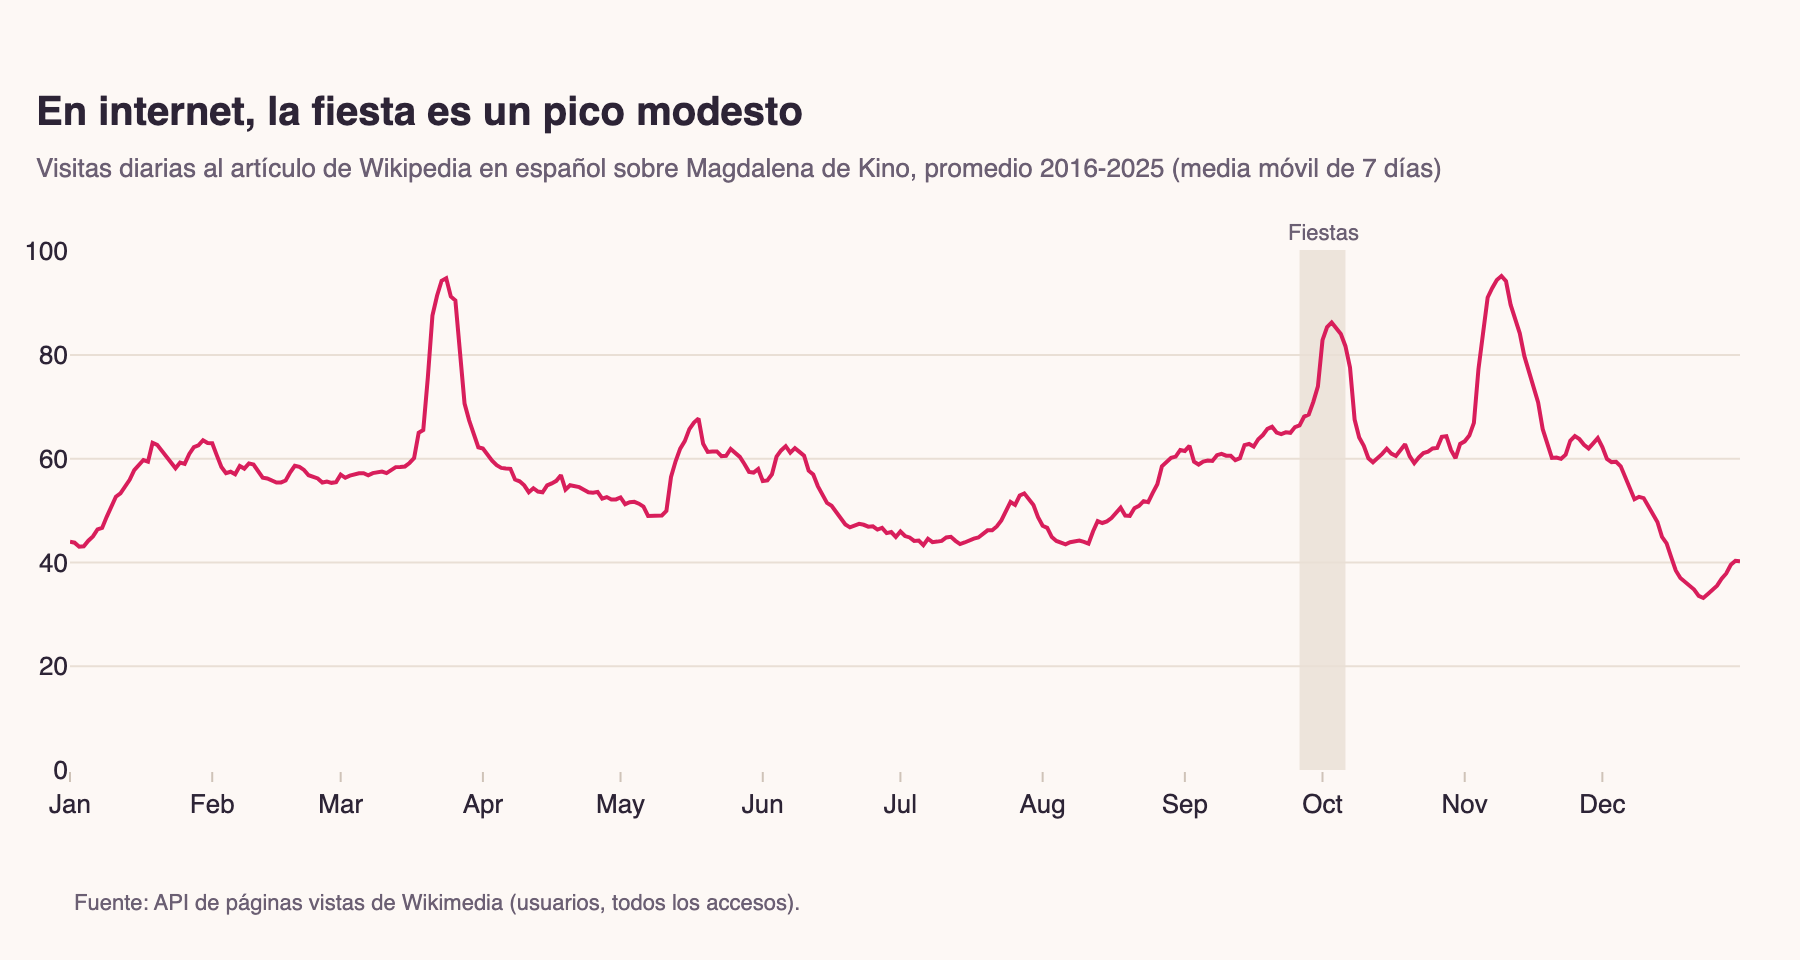

In [5]:
perfil = es[es["anio"].between(2016, 2025)].copy()
perfil["dia"] = perfil["fecha"].dt.strftime("%m-%d")
perfil = perfil[perfil["dia"] != "02-29"].groupby("dia")["visitas"].mean()
perfil.index = pd.to_datetime("2001-" + perfil.index)
suave = perfil.rolling(7, center=True, min_periods=1).mean()

fig = go.Figure()
fig.add_vrect(x0="2001-09-26", x1="2001-10-06", fillcolor=tema.CUADRICULA, opacity=0.8, line_width=0, layer="below")
fig.add_annotation(x="2001-10-01", y=1.0, yref="paper", text="Fiestas", showarrow=False, yanchor="bottom",
                   font=dict(color=tema.TEXTO_SUAVE, size=11))
fig.add_trace(go.Scatter(
    x=suave.index, y=suave.values, mode="lines", line=dict(color=tema.PROTAGONISTA, width=2),
    hovertemplate="%{x|%d %b}: %{y:.0f} visitas diarias (promedio 2016-2025)<extra></extra>", showlegend=False,
))
fig.update_layout(
    title=tema.titulo("En internet, la fiesta es un pico modesto",
                      "Visitas diarias al artículo de Wikipedia en español sobre Magdalena de Kino, promedio 2016-2025 (media móvil de 7 días)"),
    xaxis=dict(tickformat="%b", dtick="M1", title=None),
    yaxis=dict(rangemode="tozero", title=None), height=480,
)
tema.nota_fuente(fig, "Fuente: API de páginas vistas de Wikimedia (usuarios, todos los accesos).")
tema.mostrar(fig, "08_wikipedia_temporada")

**Lectura:** sí hay un pico en los días de la fiesta: de unas 60 visitas diarias a unas 85. Pero es del mismo tamaño que otros dos picos del año (finales de marzo y principios de noviembre) cuyo origen no investigamos, y nada parecido a un pueblo que se multiplica de 2 a 5 veces. La peregrinación se vive en la carretera, no en las búsquedas. Como termómetro de asistencia, Wikipedia no sirve.

## Conclusiones

- Durante las fiestas el artículo recibe en promedio unas 1.4 veces las visitas diarias del resto del año: un aumento pequeño frente a un pueblo que se multiplica de 2 a 5 veces.
- 2021 es el único año con índice menor a 1. Es consistente con que la fiesta no se celebrara con normalidad ese año, pero no lo prueba: 2020, que sí se suspendió, tuvo 1.2.
- No hay una serie digital que sustituya un conteo presencial.

In [6]:
indice.to_csv(config.DIR_PROCESSED / "wikipedia_indice_fiestas.csv")